# Panduan Colab untuk Tubes Pengolahan Citra Digital (IF2514505)

## Bagian 1 — Setting Colab

In [ ]:
#  1. Cek lingkungan & (opsional) sambungin Google Drive
import sys, os   # sys = info Python, os = urusan folder dan file

# Ubah ke True kalau mau dataset dan hasil disimpan di Google Drive (biar gak hilang)
PAKAI_DRIVE = False

if PAKAI_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')                  # bakal muncul pop-up minta izin akses Drive
    BASE_DIR = '/content/drive/MyDrive/PCD_Tubes'  # folder kerja di Drive kamu
else:
    BASE_DIR = '/content/PCD_Tubes'                # folder kerja sementara di Colab

# Bikin dua folder: satu buat dataset (masuk), satu buat hasil (keluar)
DATA_DIR = os.path.join(BASE_DIR, 'dataset')
OUT_DIR  = os.path.join(BASE_DIR, 'hasil')
os.makedirs(DATA_DIR, exist_ok=True)               # exist_ok=True: gak error kalau foldernya udah ada
os.makedirs(OUT_DIR, exist_ok=True)

print('Python   :', sys.version.split()[0])
print('Folder   :', BASE_DIR)

Python   : 3.13.18
Folder   : /content/PCD_Tubes


## Bagian 2 — Import library

Library itu kumpulan alat siap pakai. Di Colab semuanya udah terpasang, tinggal dipanggil:

| Library | Gunanya |
|---|---|
| **NumPy** | Gambar itu sebenarnya cuma tabel angka. NumPy yang ngurusin tabel angka itu |
| **OpenCV (`cv2`)** | Baca gambar, ubah ke abu-abu, filter, CLAHE, dll |
| **Matplotlib** | Nampilin gambar dan grafik |
| **Pandas** | Bikin tabel ringkasan biar rapi |
| **scikit-image** | Nyediain gambar contoh bawaan |

Versi tiap library dicetak juga, soalnya hasil angka bisa sedikit beda antar versi. Versi ini enak dicantumin di laporan.

In [ ]:
#  2. Import library
import glob                       # buat nyari file berdasarkan pola nama (misal *.jpg)
import numpy as np                # gambar = array NumPy (tabel angka)
import cv2                        # OpenCV: baca/tulis gambar, filter, CLAHE
import pandas as pd               # tabel ringkasan buat EDA
import matplotlib
import matplotlib.pyplot as plt   # nampilin gambar dan histogram
from skimage import data          # gambar contoh bawaan (gak perlu download)

# Cetak versi (biar bisa dilaporkan, dan hasil bisa direproduksi)
print('NumPy      :', np.__version__)
print('OpenCV     :', cv2.__version__)
print('Matplotlib :', matplotlib.__version__)
print('Pandas     :', pd.__version__)

# Seed acak dikunci biar derau yang dibangkitin hasilnya selalu sama tiap dijalankan
RNG = np.random.default_rng(2026)
plt.rcParams['figure.dpi'] = 100  # biar gambar di Colab agak tajam

NumPy      : 2.4.6
OpenCV     : 4.14.0
Matplotlib : 3.10.0
Pandas     : 2.2.3


## Bagian 3 — Cari dan muat dataset

### Cari dataset di mana?
- **Kaggle**: https://www.kaggle.com/datasets (filter *Computer Vision*)
- **Roboflow Universe**: https://universe.roboflow.com (banyak dataset deteksi objek)
- **Hugging Face Datasets**: https://huggingface.co/datasets
- **Google Dataset Search**: https://datasetsearch.research.google.com
- Atau punya sendiri, misalnya foto lapangan, citra satelit, data dari instansi.

### Cara milih dataset yang bagus
- Topiknya nyambung sama tubes kamu.
- **Lisensinya jelas**, boleh dipakai buat tugas atau penelitian.
- Jumlah dan kualitas gambarnya cukup.
- Kalau butuh label (misal kelas atau kotak objek), pastikan ada.
- Catat sumber, link, dan lisensinya buat laporan.

### Tiga cara masukin dataset ke Colab
Atur variabel `SUMBER` di sel bawah:
- `'bawaan'`: pakai gambar contoh scikit-image. **Ini default, langsung jalan.**
- `'upload'`: upload gambar atau file `.zip` dari laptop kamu.
- `'kaggle'`: download langsung dari Kaggle. Butuh file `kaggle.json` (Kaggle → Settings → API → Create New Token).

In [ ]:
#  3a. Pilih sumber dataset
SUMBER = 'bawaan'                        # pilih salah satu: 'bawaan' | 'upload' | 'kaggle'
KAGGLE_DATASET = 'pemilik/nama-dataset'  # diisi kalau SUMBER = 'kaggle' (format: pemilik/nama)

if SUMBER == 'upload':
    from google.colab import files
    import zipfile
    terunggah = files.upload()           # muncul tombol pilih file (gambar .jpg/.png atau satu .zip)
    for nama in terunggah:
        if nama.lower().endswith('.zip'):
            with zipfile.ZipFile(nama) as z:
                z.extractall(DATA_DIR)   # kalau zip, ekstrak ke folder dataset
        else:
            os.replace(nama, os.path.join(DATA_DIR, nama))  # kalau gambar biasa, pindahin ke folder dataset

elif SUMBER == 'kaggle':
    from google.colab import files
    if not os.path.exists('/root/.kaggle/kaggle.json'):
        print('Upload kaggle.json kamu:')
        files.upload()
        os.makedirs('/root/.kaggle', exist_ok=True)
        os.replace('kaggle.json', '/root/.kaggle/kaggle.json')
        os.chmod('/root/.kaggle/kaggle.json', 0o600)   # izin file wajib 600, kalau gak Kaggle nolak
    # download dataset lalu otomatis di-unzip ke folder dataset
    os.system(f'kaggle datasets download -d {KAGGLE_DATASET} -p {DATA_DIR} --unzip')

print('Sumber dataset:', SUMBER)

Sumber dataset: bawaan


Sel berikut ngumpulin semua gambar ke satu kamus (dictionary) Python: `{nama_file: array_gambar}`. Ada dua hal penting:

- **OpenCV baca gambar dengan urutan warna BGR**, sedangkan Matplotlib pakai RGB. Makanya kita ubah ke RGB biar warnanya gak aneh (biru jadi oranye).
- Gambar abu-abu diduplikasi jadi 3 kanal supaya semua gambar punya bentuk yang sama.

In [ ]:
#  3b. Muat gambar jadi kamus {nama: array RGB uint8}
def muat_folder(folder, maks=12):
    # Baca semua gambar di dalam folder (termasuk subfolder), paling banyak `maks` file
    ekstensi = ('*.jpg', '*.jpeg', '*.png', '*.bmp', '*.tif', '*.tiff')
    jalur = []
    for e in ekstensi:
        jalur += glob.glob(os.path.join(folder, '**', e), recursive=True)  # cari rekursif
    jalur = sorted(jalur)[:maks]                  # urutkan lalu batasi jumlahnya
    hasil = {}
    for p in jalur:
        bgr = cv2.imread(p, cv2.IMREAD_COLOR)     # OpenCV baca dalam urutan BGR
        if bgr is None:                           # kalau file rusak, lewati aja
            print('Gagal dibaca:', p)
            continue
        hasil[os.path.basename(p)] = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)  # ubah BGR -> RGB
    return hasil

def ke_rgb(a):
    # Pastikan gambar bertipe uint8 dan punya 3 kanal (abu-abu diduplikasi 3x)
    a = a.astype(np.uint8)
    return np.stack([a, a, a], axis=-1) if a.ndim == 2 else a

if SUMBER == 'bawaan':
    citra = {
        'camera':    ke_rgb(data.camera()),      # abu-abu 512x512, orang bawa kamera
        'coffee':    ke_rgb(data.coffee()),      # berwarna, secangkir kopi
        'astronaut': ke_rgb(data.astronaut()),   # berwarna, astronot
        'moon':      ke_rgb(data.moon()),        # abu-abu, kontras rendah (bagus buat latihan)
        'page':      ke_rgb(data.page()),        # foto dokumen teks
    }
else:
    citra = muat_folder(DATA_DIR)                # kalau upload/kaggle, baca dari folder dataset

# Berhenti dengan pesan jelas kalau gak ada gambar sama sekali
assert len(citra) > 0, 'Gak ada gambar ditemukan. Cek SUMBER dan isi folder dataset.'
print(f'{len(citra)} gambar dimuat:', list(citra.keys()))

5 gambar dimuat: ['camera', 'coffee', 'astronaut', 'moon', 'page']


## Bagian 4 — Fungsi bantu (alat ukur)

Di modul ada asas: **setiap klaim harus ada angkanya**. Jadi bukan cuma bilang gambarnya jadi lebih bagus, tapi harus dibuktiin pakai ukuran. Ini empat ukuran yang kita pakai:

| Ukuran | Artinya dengan bahasa sederhana |
|---|---|
| **Simpangan baku (std)** | Ukuran kontras. Makin besar, makin beda antara gelap dan terang |
| **Entropi** | Ukuran seberapa merata tingkat terang-gelap tersebar. Turun kalau banyak tingkat yang digabung |
| **Aras terpakai** | Jumlah tingkat terang-gelap yang beneran muncul di gambar (maks 256) |
| **PSNR** | Seberapa mirip hasil dengan gambar asli yang bersih. Satuan dB, **makin tinggi makin mirip** |

In [ ]:
#  4. Fungsi bantu
def ke_abu(rgb):
    # Ubah gambar warna jadi abu-abu: Y = 0.299R + 0.587G + 0.114B
    return cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)

def entropi(im):
    # Entropi Shannon H = -sum(p * log2 p), satuan bit
    h = np.bincount(im.ravel(), minlength=256).astype(np.float64)  # hitung berapa piksel per nilai 0..255
    p = h / h.sum()                                                # ubah jadi peluang
    p = p[p > 0]                                                   # buang yang 0 biar log2 gak error
    return float(-(p * np.log2(p)).sum())

def aras_terpakai(im):
    # Hitung ada berapa nilai intensitas yang beda-beda di gambar
    return int(len(np.unique(im)))

def psnr(ref, im):
    # PSNR = 10 log10(255^2 / MSE). MSE = rata-rata kuadrat selisih dengan gambar acuan
    mse = np.mean((ref.astype(np.float64) - im.astype(np.float64)) ** 2)
    return float('inf') if mse == 0 else float(10 * np.log10(255.0 ** 2 / mse))

def ringkas(nama, im):
    # Satu baris ringkasan statistik gambar abu-abu (dipakai buat bikin tabel)
    return {'varian': nama, 'min': int(im.min()), 'maks': int(im.max()),
            'rerata': round(float(im.mean()), 2), 'std': round(float(im.std()), 2),
            'aras': aras_terpakai(im), 'entropi': round(entropi(im), 3)}

def tampil(daftar, judul=None, kolom=4, ukuran=3.2):
    # Tampilin banyak gambar sekaligus dalam satu grid. daftar = [(judul, array), ...]
    n = len(daftar)
    baris = int(np.ceil(n / kolom))
    fig, ax = plt.subplots(baris, kolom, figsize=(ukuran * kolom, ukuran * baris))
    ax = np.atleast_1d(ax).ravel()
    for a in ax:
        a.axis('off')                                   # sembunyiin sumbu dulu (biar kotak kosong gak muncul)
    for a, (t, im) in zip(ax, daftar):
        if im.ndim == 2:
            a.imshow(im, cmap='gray', vmin=0, vmax=255) # skala dikunci 0-255 biar perbandingannya adil
        else:
            a.imshow(im)
        a.set_title(t, fontsize=9)
    if judul:
        fig.suptitle(judul)
    plt.tight_layout()
    plt.show()

## Bagian 5 — EDA (Exploratory Data Analysis)

EDA itu intinya **kenalan dulu sama datanya sebelum diolah**. Yang dicek:
- ukuran gambar (apakah seragam?),
- tipe data dan jumlah kanal,
- rentang nilai piksel (min dan maks),
- kontras (std) dan terang-gelapnya (rerata),
- bentuk histogram.

Hasil EDA yang nentuin preprocessing apa yang perlu dipakai. Jadi jangan dilewatin ya.

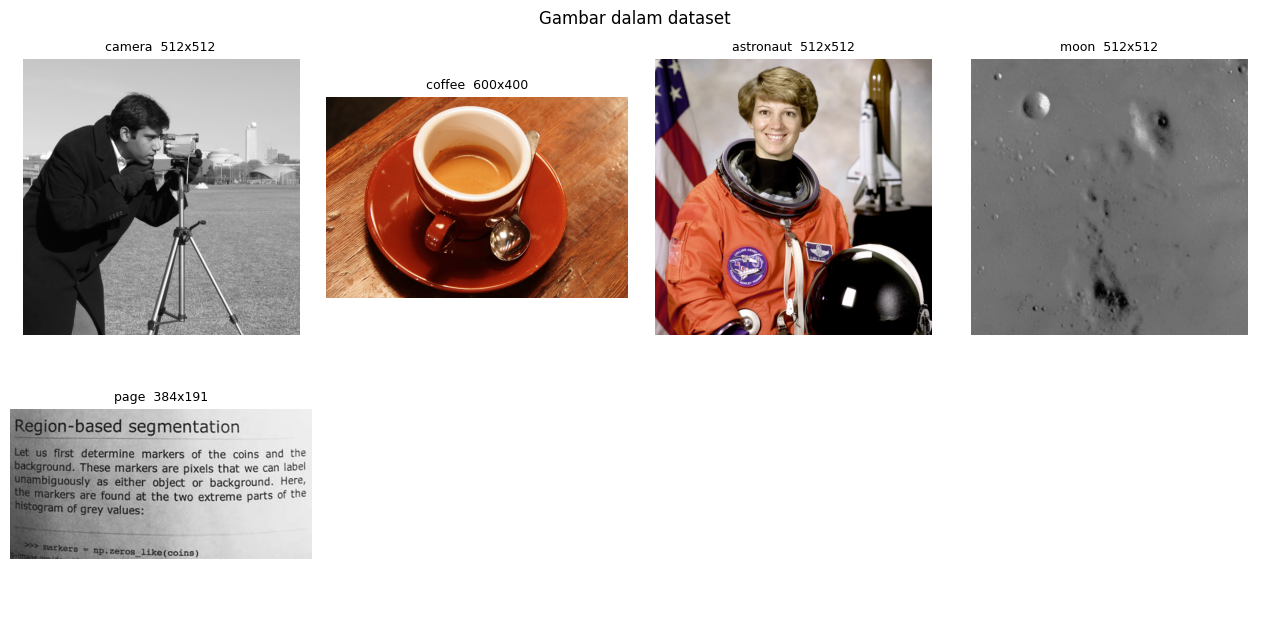

In [ ]:
#  5a. Lihat semua gambar dulu (cek visual)
tampil([(f'{k}  {v.shape[1]}x{v.shape[0]}', v) for k, v in citra.items()],
       judul='Gambar dalam dataset')

Sekarang tabel ringkasannya. **Cara bacanya:**
- `std` kecil atau rentang `min–maks` sempit → **kontras rendah** → cocok dicoba peregangan kontras, HE, atau CLAHE.
- `rerata` terlalu kecil → gambar **gelap**, terlalu besar → **terang** → cocok dicoba gamma.
- Ukuran antar gambar beda-beda → harus **di-resize seragam** sebelum masuk model.

In [ ]:
#  5b. Tabel ringkasan EDA
baris = []
for nama, rgb in citra.items():
    g = ke_abu(rgb)                                   # statistik dihitung di versi abu-abu
    baris.append({
        'nama': nama,
        'tinggi': rgb.shape[0], 'lebar': rgb.shape[1],
        'kanal': rgb.shape[2], 'dtype': str(rgb.dtype),
        'min': int(g.min()), 'maks': int(g.max()),
        'rerata': round(float(g.mean()), 2),          # terang-gelap rata-rata
        'std (kontras)': round(float(g.std()), 2),    # makin kecil = makin kusam
        'aras unik': aras_terpakai(g),
        'entropi (bit)': round(entropi(g), 3),
    })
df_eda = pd.DataFrame(baris)
display(df_eda)

,nama,tinggi,lebar,kanal,dtype,min,maks,rerata,std (kontras),aras unik,entropi (bit)
0,camera,512,512,3,uint8,0,255,129.06,73.64,256,7.232
1,coffee,400,600,3,uint8,0,255,103.65,58.12,256,7.658
2,astronaut,512,512,3,uint8,0,255,115.41,75.12,256,7.454
3,moon,512,512,3,uint8,0,255,112.17,13.33,178,4.885
4,page,191,384,3,uint8,0,255,171.54,56.81,255,7.444


**Histogram** = grafik batang yang nunjukin berapa banyak piksel di tiap tingkat terang-gelap (kiri = gelap, kanan = terang). Garis putus-putus oranye itu **CDF** (jumlah kumulatif), dan CDF inilah yang dipakai histogram equalization.

Cara bacanya:
- Batang numpuk di satu sisi atau sempit → gambar **kusam** atau pencahayaannya jelek.
- Batang nyebar dari kiri sampai kanan → kontras udah bagus.

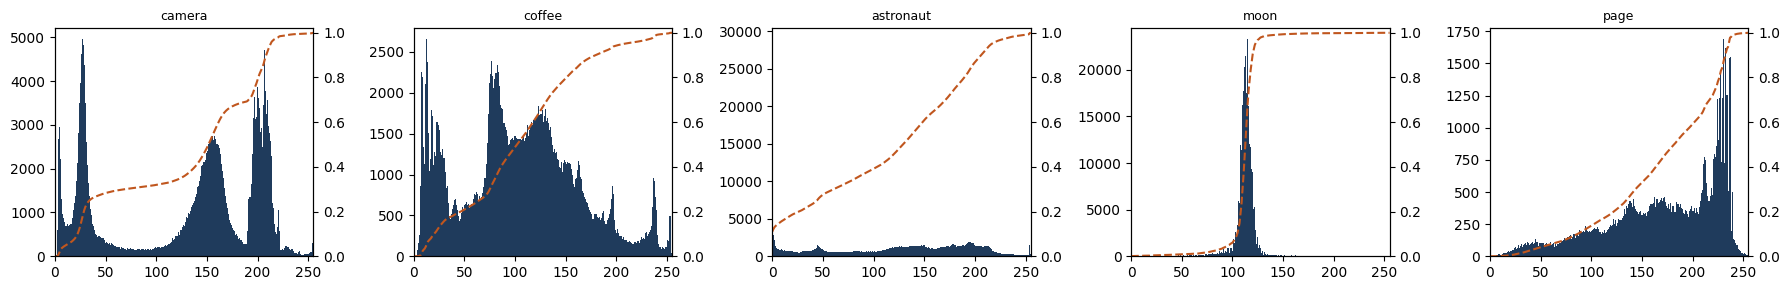

In [ ]:
#  5c. Histogram + CDF tiap gambar (abu-abu)
n = len(citra)
fig, ax = plt.subplots(1, n, figsize=(3.6 * n, 3))
ax = np.atleast_1d(ax)
for a, (nama, rgb) in zip(ax, citra.items()):
    g = ke_abu(rgb)
    h = np.bincount(g.ravel(), minlength=256)                  # banyak piksel per nilai 0..255
    a.bar(range(256), h, width=1.0, color='#1f3b5c')           # batang = histogram
    a2 = a.twinx()                                             # sumbu kedua biar CDF skalanya 0..1
    a2.plot(np.cumsum(h) / h.sum(), color='#c0561e', ls='--')  # garis putus = CDF
    a2.set_ylim(0, 1.02)
    a.set_title(nama, fontsize=9)
    a.set_xlim(0, 255)
plt.tight_layout()
plt.show()

## Bagian 6 — Digitalisasi citra: sampling dan kuantisasi

Gambar di dunia nyata itu **kontinu** (mulus, gak ada kotak-kotak). Biar bisa disimpan di komputer, gambar harus dipotong-potong jadi angka. Ada dua proses:

1. **Sampling** = motong gambar jadi **grid piksel** (urusan *posisi*). Makin sedikit piksel, makin kasar dan detail makin hilang.
2. **Kuantisasi** = ngebulatin tingkat terang-gelap jadi **sejumlah tingkat tertentu, L aras** (urusan *warna/kecerahan*). Makin sedikit tingkat, makin muncul garis-garis pita palsu (*false contour*).

Analogi: sampling itu kayak nentuin jumlah kotak di kertas kotak-kotak, kuantisasi itu kayak nentuin jumlah warna pensil yang boleh dipakai.

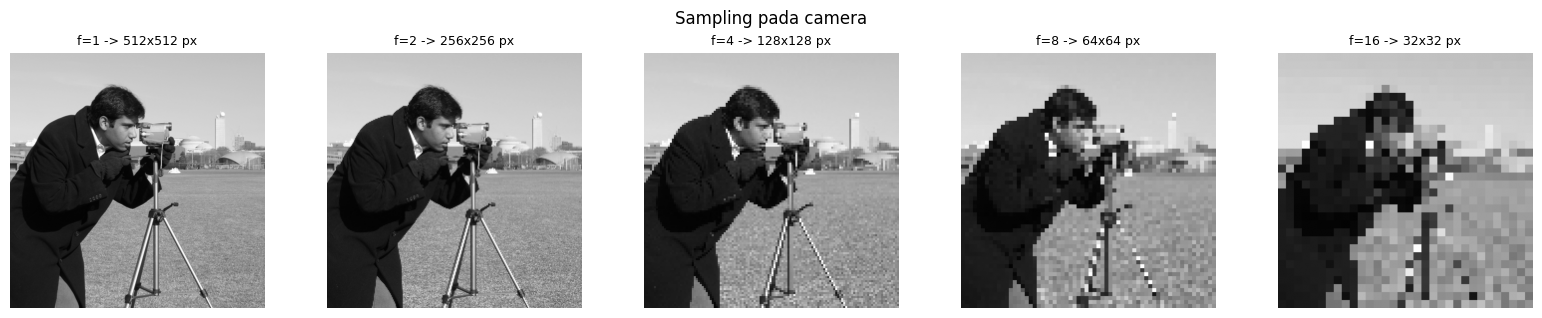

In [ ]:
#  6a. Sampling: kurangi resolusi (jumlah piksel)
pilih = list(citra.keys())[0]            # pakai gambar pertama buat demo
g = ke_abu(citra[pilih])

hasil_sampling = []
for f in [1, 2, 4, 8, 16]:
    kecil = g[::f, ::f]                  # ambil tiap f piksel aja (f=2 -> piksel tinggal 1/4)
    # Dibesarin lagi pakai 'nearest' biar kotak-kotak pikselnya kelihatan jelas
    besar = cv2.resize(kecil, (g.shape[1], g.shape[0]), interpolation=cv2.INTER_NEAREST)
    hasil_sampling.append((f'f={f} -> {kecil.shape[1]}x{kecil.shape[0]} px', besar))
tampil(hasil_sampling, judul=f'Sampling pada {pilih}', kolom=5)

**Hasilnya:** makin besar `f`, makin sedikit piksel dan makin kotak-kotak. Detail halus (garis tipis, tulisan kecil) hilang duluan.

Sekarang kuantisasi. Di tabelnya, perhatiin PSNR turun dan entropinya turun juga, artinya makin banyak informasi yang hilang.

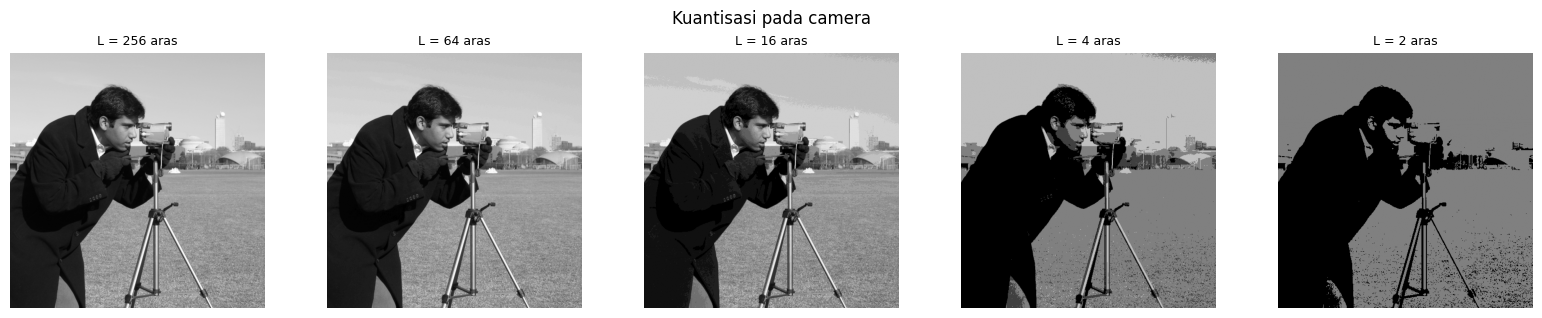

,L,aras terpakai,entropi,PSNR vs asli (dB)
0,256,256,7.232,inf
1,64,64,5.258,42.74
2,16,16,3.393,29.22
3,4,4,1.817,19.27
4,2,2,0.940,13.19


In [ ]:
#  6b. Kuantisasi: kurangi jumlah tingkat keabuan
hasil_kuant = []
tabel_kuant = []
for L in [256, 64, 16, 4, 2]:
    langkah = 256 // L                                 # lebar tiap 'keranjang' tingkat
    q = ((g // langkah) * langkah).astype(np.uint8)    # banyak nilai digabung ke satu nilai (banyak-ke-satu)
    hasil_kuant.append((f'L = {L} aras', q))
    tabel_kuant.append({'L': L, 'aras terpakai': aras_terpakai(q),
                        'entropi': round(entropi(q), 3),
                        'PSNR vs asli (dB)': round(psnr(g, q), 2)})  # inf = identik dengan asli
tampil(hasil_kuant, judul=f'Kuantisasi pada {pilih}', kolom=5)
display(pd.DataFrame(tabel_kuant))

## Bagian 7 — Preprocessing

Preprocessing itu **beres-beres gambar sebelum dipakai** (buat model atau analisis berikutnya). Kita bagi tiga bagian:

- **7A. Perbaiki kontras**: transformasi intensitas (negatif, log, gamma, peregangan), histogram equalization (HE), dan CLAHE.
- **7B. Atasi derau**: filter penghalus (rerata, Gaussian, median), lalu penajaman (unsharp masking).
- **7C. Pipeline akhir**: gabungin langkah terbaik, jalankan ke semua gambar, lalu simpan hasilnya.

Pesan penting: **gak ada satu metode yang selalu paling bagus.** Pilihnya harus berdasarkan angka (std, entropi, PSNR), bukan sekadar kelihatan lebih bagus di mata.

### 7A.1 Transformasi intensitas pakai LUT

**LUT (look-up table)** itu tabel contekan: untuk tiap nilai 0–255 kita siapin nilai penggantinya sekali aja, lalu semua piksel tinggal *dicari di tabel* (`lut[gambar]`). Jauh lebih cepat daripada ngitung ulang rumus di tiap piksel.

Transformasi yang dibuat:

| Transformasi | Efeknya |
|---|---|
| **Negatif** | Gelap jadi terang, terang jadi gelap (kayak negatif film) |
| **Log** | Ngangkat bagian gelap, bagian terang dikempesin |
| **Gamma < 1** (misal 0,5) | Gambar jadi lebih **terang** |
| **Gamma > 1** (misal 2,0) | Gambar jadi lebih **gelap** |
| **Min–maks** | Ngelarin rentang nilai gambar sampai pas 0–255 (kontras naik) |

Di akhir ada uji cepat. Kalau semuanya `True`, berarti implementasinya benar sesuai angka di modul.

In [ ]:
#  7A.1 Transformasi intensitas lewat LUT (look-up table)
# Hitung pemetaan sekali untuk semua 256 nilai, lalu pakai lut[gambar] (cepat banget).
# Aturan pembulatan: floor(x + 0.5)
r = np.arange(256, dtype=np.float64)       # semua kemungkinan nilai masukan: 0, 1, ..., 255

def bulat(x):
    # Bulatkan, batasi ke 0..255, lalu ubah ke uint8
    return np.clip(np.floor(x + 0.5), 0, 255).astype(np.uint8)

lut_negatif = bulat(255 - r)                            # s = 255 - r            (Eq. 3-2)
lut_log     = bulat((255 / np.log(256)) * np.log1p(r))  # s = c * log(1 + r)     (Eq. 3-4), c = 255/log(256)

def lut_gamma(g):
    return bulat(255 * (r / 255) ** g)                  # s = 255 * (r/255)^gamma (Eq. 3-5)

def lut_minmaks(im):
    lo, hi = float(im.min()), float(im.max())           # nilai terendah dan tertinggi di gambar
    return bulat((r - lo) / (hi - lo) * 255)            # regangkan [min, maks] jadi [0, 255]

def lut_sepotong(r1, s1, r2, s2):
    # Peregangan sepotong-sepotong: tentuin sendiri titik belok kurvanya
    return bulat(np.interp(r, [0, r1, r2, 255], [0, s1, s2, 255]))

# Uji cepat (acuan dari modul): harus tercetak True True True True
print(lut_negatif[0] == 255, lut_gamma(0.5)[64] == 128,
      lut_gamma(2.0)[64] == 16, lut_log[10] == 110)

True True True True


### 7A.2 Histogram Equalization (HE)

**Ide HE:** kalau histogram numpuk di satu area (gambar kusam), kita **ratakan sebarannya** ke seluruh rentang 0–255 biar kontras naik. Langkahnya:

1. Hitung histogram (berapa piksel per nilai).
2. Ubah jadi peluang (bagi total piksel).
3. Jumlahkan kumulatif (**CDF**).
4. Kalikan dengan 255, bulatkan. Hasilnya jadi tabel pengganti nilai (LUT).

Kita tulis dari rumus sendiri (Eq. 3-15) lalu **bandingin dengan fungsi bawaan OpenCV** (`cv2.equalizeHist`). Kalau ada selisih kecil, itu karena OpenCV pakai variasi rumus (nilai terendah dipaksa jadi 0), **bukan berarti rumus kita salah.**

In [ ]:
#  7A.2 Histogram equalization dari rumus (Eq. 3-15)
def lut_he(im, L=256):
    h = np.bincount(im.ravel(), minlength=L).astype(np.float64)  # 1) histogram
    p = h / h.sum()                                              # 2) jadi peluang
    cdf = np.cumsum(p)                                           # 3) jumlah kumulatif
    return np.floor((L - 1) * cdf + 0.5).astype(np.uint8)        # 4) (L-1) x CDF, dibulatkan

# Uji pada contoh 8 aras dari modul: pemetaan yang benar = [1 3 5 6 6 7 7 7]
contoh = np.repeat(np.arange(8), [790, 1023, 850, 656, 329, 245, 122, 81]).astype(np.uint8)
print('Pemetaan contoh:', lut_he(contoh, 8))

# Bandingkan dengan fungsi bawaan OpenCV
g = ke_abu(citra[list(citra.keys())[0]])
punyaku = lut_he(g)[g]                       # hasil implementasi kita
pustaka = cv2.equalizeHist(g)                # hasil OpenCV
print('Piksel berbeda vs cv2.equalizeHist:', int((punyaku != pustaka).sum()),
      '| selisih maks:', int(np.abs(punyaku.astype(int) - pustaka.astype(int)).max()))
# Kalau ada beda: OpenCV pakai (cdf - cdf_min)/(N - cdf_min), jadi aras terendah dipetakan ke 0.
# Itu cuma variasi rumus, bukan berarti implementasi Eq. 3-15 kita salah.

Pemetaan contoh: [1 3 5 6 6 7 7 7]
Piksel berbeda vs cv2.equalizeHist: 0 | selisih maks: 0


### 7A.3 Adu semua metode perbaikan kontras

Semua metode kita coba di satu gambar berkontras rendah (`moon`), lalu dibandingkan pakai angka. Ada satu metode baru:

- **CLAHE** = HE yang dikerjain **per kotak kecil** (di sini 8×8 kotak) dan ada **batas penguatan (`clipLimit`)** biar derau gak ikut meledak. Cocok buat gambar yang cahayanya gak rata (ada bagian gelap dan bagian terang sekaligus). HE biasa (global) sering gagal di kasus itu.

**Cara baca tabel hasil:**
- `std` naik → kontras naik (bagus).
- `aras` dan `entropi` turun → ada tingkat yang digabung, ada informasi yang hilang.
- HE global biasanya bikin std naik banget tapi arasnya jadi sedikit. Itu *harga* yang dibayar.

Catatan penting: **gambar yang nilai pikselnya mau diukur** (misalnya citra medis atau citra radiometrik) **jangan diekualisasi**, karena nilai aslinya jadi berubah dan gak bisa dipercaya lagi buat pengukuran.

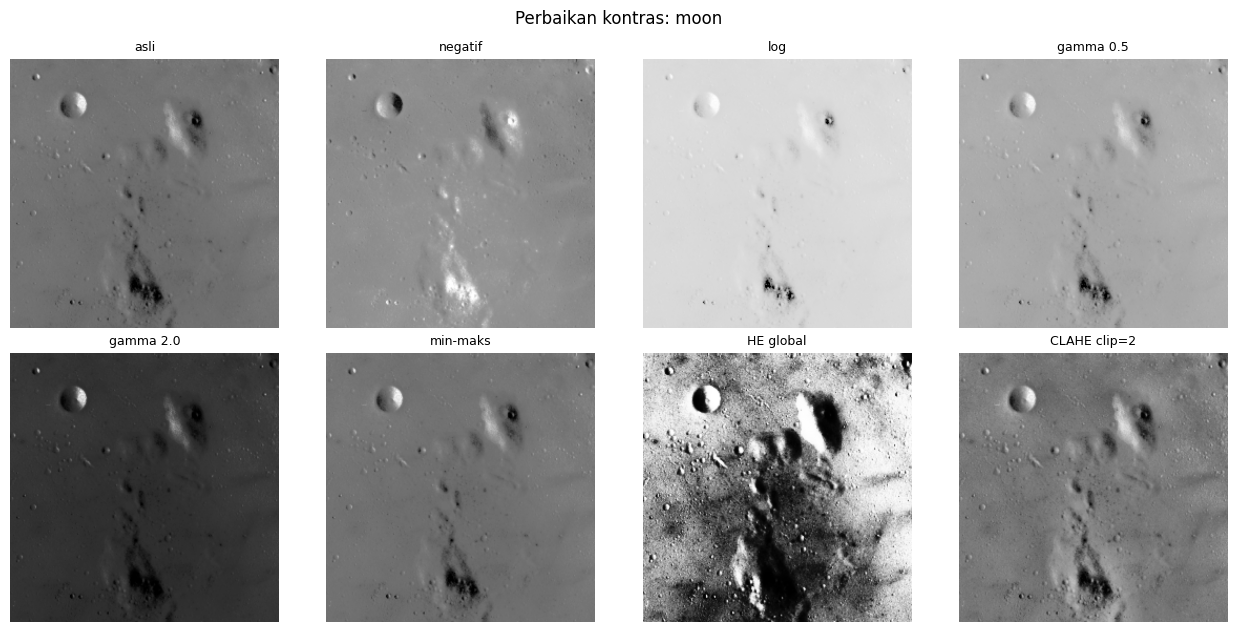

,varian,min,maks,rerata,std,aras,entropi
0,asli,0,255,112.17,13.33,178,4.885
1,negatif,0,255,142.83,13.33,178,4.885
2,log,0,255,216.85,10.47,105,3.597
3,gamma 0.5,0,255,168.58,12.35,154,4.428
4,gamma 2.0,0,255,50.03,11.16,138,4.646
5,min-maks,0,255,112.17,13.33,178,4.885
6,HE global,0,255,133.89,73.90,49,4.720
7,CLAHE clip=2,1,255,119.94,18.53,246,5.826


In [ ]:
#  7A.3 Bandingkan perbaikan kontras di satu gambar
# Pakai 'moon' (kontras rendah) kalau ada, kalau gak ada pakai gambar pertama
nama_uji = 'moon' if 'moon' in citra else list(citra.keys())[0]
g = ke_abu(citra[nama_uji])

# CLAHE: HE per kotak 8x8, clipLimit=2.0 = batas penguatan (makin besar makin agresif)
clahe2 = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))

varian = {
    'asli':         g,
    'negatif':      lut_negatif[g],
    'log':          lut_log[g],
    'gamma 0.5':    lut_gamma(0.5)[g],
    'gamma 2.0':    lut_gamma(2.0)[g],
    'min-maks':     lut_minmaks(g)[g],
    'HE global':    lut_he(g)[g],
    'CLAHE clip=2': clahe2.apply(g),
}
tampil([(k, v) for k, v in varian.items()], judul=f'Perbaikan kontras: {nama_uji}', kolom=4)
display(pd.DataFrame([ringkas(k, v) for k, v in varian.items()]))
# Baca angka: std naik = kontras naik; entropi/aras turun = ada tingkat yang menyatu (info hilang).

### 7B.1 Filter spasial: korelasi buatan sendiri

**Filter** itu kerjanya: geser jendela kecil (**kernel**, di sini 3×3) ke seluruh gambar, di tiap posisi hitung rata-rata berbobot dari piksel di sekitarnya. Itu namanya **korelasi**. (Konvolusi itu sama, tapi kernelnya dibalik dulu.)

Kita tulis sendiri tanpa perulangan per piksel (pakai trik jumlahin 9 gambar yang digeser), lalu cek hasilnya sama dengan `cv2.filter2D`. Selisihnya harus **hampir nol (< 1e-9)**.

Di tepi gambar, jendela keluar dari batas, jadi tepinya kita **replikasi** (nilai piksel tepi diulang) biar tetap bisa dihitung.

In [ ]:
#  7B.1 Korelasi 3x3 buatan sendiri
def korelasi3(f, w):
    # Korelasi kernel 3x3 dengan padding replikasi tepi, tanpa loop per piksel
    f = f.astype(np.float64)                       # hitung di float biar gak ada pembulatan dini
    p = np.pad(f, 1, mode='edge')                  # tambah bingkai 1 piksel, isinya salinan nilai tepi
    H, W = f.shape
    out = np.zeros_like(f)
    for i in range(3):
        for j in range(3):
            out += w[i, j] * p[i:i + H, j:j + W]   # tambah gambar yang digeser (i,j) x bobot kernel
    return out

w_rata = np.ones((3, 3)) / 9.0                     # kernel rerata 3x3: semua bobot sama (1/9)
uji = g.astype(np.float64)
ref = cv2.filter2D(uji, -1, w_rata, borderType=cv2.BORDER_REPLICATE)  # versi OpenCV sebagai pembanding
print('Selisih maks vs cv2.filter2D:', np.abs(korelasi3(uji, w_rata) - ref).max(), '(harus < 1e-9)')

Selisih maks vs cv2.filter2D: 0.0 (harus < 1e-9)


### 7B.2 Pilih filter penghalus

Kita bikin gambar **berderau** dari gambar bersih (ditambah derau Gaussian dan derau **garam-merica**, yaitu bintik putih dan hitam acak). Lalu tiap filter dicoba dan dinilai pakai **PSNR terhadap gambar bersih** (makin tinggi makin bagus).

Kenalan sama filternya:
- **Rerata (blur)**: tiap piksel diganti rata-rata tetangganya. Sederhana tapi bikin gambar buram.
- **Gaussian**: rata-rata berbobot, tetangga yang dekat bobotnya lebih besar. Lebih halus.
- **Median**: tiap piksel diganti **nilai tengah** tetangganya. Bintik ekstrem (putih/hitam) kebuang total karena gak ikut dirata-rata.

**Kenapa median biasanya menang di derau garam-merica?** Misal tetangganya `[50, 52, 255, 49, 51]`. Rata-ratanya ketarik ke atas gara-gara si 255, tapi mediannya tetap sekitar 51. Harga yang dibayar median ukuran besar (5×5): **detail halus ikut hilang**.

,penapis,PSNR (dB)
0,median 5x5,35.35
1,median 3x3,33.04
2,Gaussian 9x9 s=1.5,32.25
3,rerata 5x5,31.80
4,rerata 3x3,28.24
5,Gaussian 5x5 s=0.8,27.84
6,berderau (tanpa filter),19.01


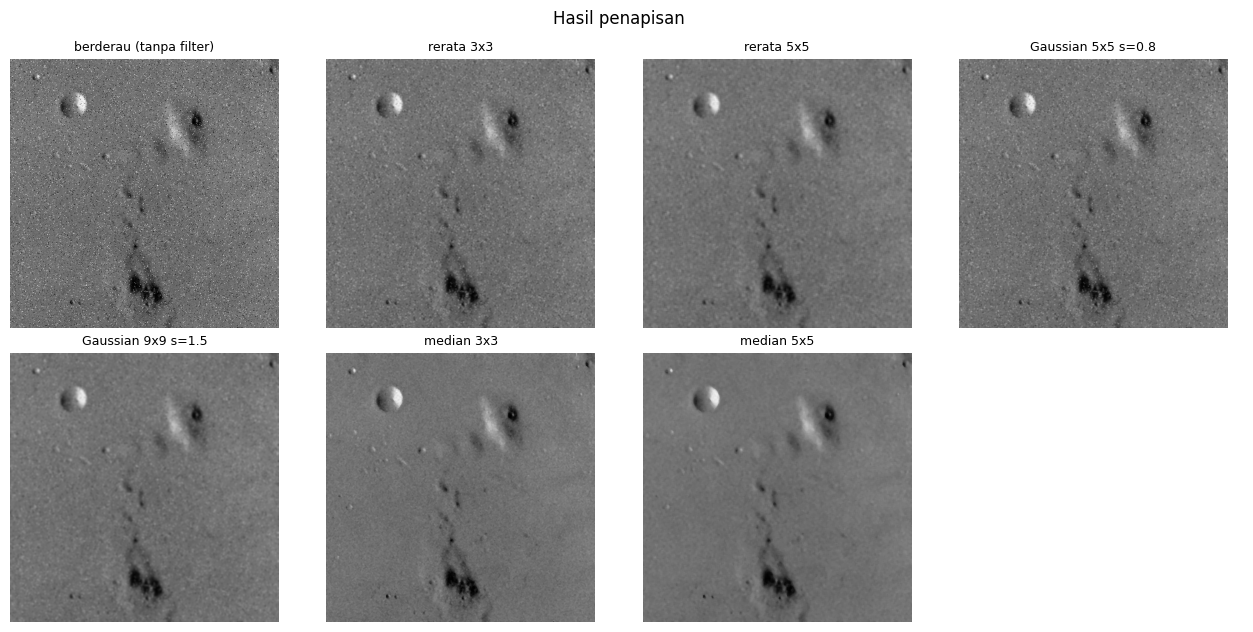

In [ ]:
#  7B.2 Bandingkan filter penghalus pada gambar berderau
bersih = g                                              # gambar acuan yang dianggap bersih

# Bikin derau: Gaussian (sigma=12) + garam-merica (total 4%), seed dikunci biar konsisten
rng = np.random.default_rng(2026)
derau = bersih.astype(np.float64) + rng.normal(0, 12, bersih.shape)   # derau Gaussian
masker = rng.random(bersih.shape)                       # angka acak 0..1 per piksel
derau[masker < 0.02] = 0                                # 2% piksel jadi hitam (pepper)
derau[masker > 0.98] = 255                              # 2% piksel jadi putih (salt)
berderau = np.clip(derau, 0, 255).astype(np.uint8)      # batasi 0..255 baru ke uint8

penapis = {
    'berderau (tanpa filter)': berderau,
    'rerata 3x3':              cv2.blur(berderau, (3, 3)),
    'rerata 5x5':              cv2.blur(berderau, (5, 5)),
    'Gaussian 5x5 s=0.8':      cv2.GaussianBlur(berderau, (5, 5), 0.8),
    'Gaussian 9x9 s=1.5':      cv2.GaussianBlur(berderau, (9, 9), 1.5),
    'median 3x3':              cv2.medianBlur(berderau, 3),
    'median 5x5':              cv2.medianBlur(berderau, 5),
}
# Tabel PSNR diurutkan dari yang tertinggi (paling mirip gambar bersih)
tabel = pd.DataFrame([{'penapis': k, 'PSNR (dB)': round(psnr(bersih, v), 2)} for k, v in penapis.items()])
display(tabel.sort_values('PSNR (dB)', ascending=False).reset_index(drop=True))
tampil([(k, v) for k, v in penapis.items()], judul='Hasil penapisan', kolom=4)

### 7B.3 Penajaman: unsharp masking

Kebalikan dari menghaluskan: **menajamkan** biar tepi dan detail lebih tegas. Rumus *unsharp masking*:

`hasil = asli + k × (asli − versi_halus)`

Intinya: ambil bagian detail (selisih asli dan versi halusnya), lalu **tambahkan lagi ke gambar** sebanyak `k` kali. Makin besar `k`, makin tajam.

Tapi hati-hati:
- `k` terlalu besar → banyak piksel nilainya lewat 255 atau di bawah 0, lalu **terpotong (clip)**, dan hasilnya jadi lebay. Kita ukur lewat `% terpotong`.
- **Jangan menajamkan gambar berderau tanpa dihaluskan dulu**, karena derau juga ikut diperkuat.
- Hitungnya wajib di `float64`. Baru di akhir di-clip ke 0–255 dan diubah ke `uint8`, biar gak ada nilai yang terpotong sebelum waktunya.

Cara milih `k`: lihat **dua angka sekaligus**, PSNR (kemiripan ke gambar bersih) dan % terpotong. `k` terbaik = PSNR tertinggi dengan potongan yang masih kecil.

,k,PSNR (dB),% terpotong
0,0.5,39.29,0.00
1,1.0,39.56,0.01
2,2.5,40.11,0.03
3,5.0,39.44,0.09
4,8.0,37.27,0.18
5,12.0,34.29,0.30


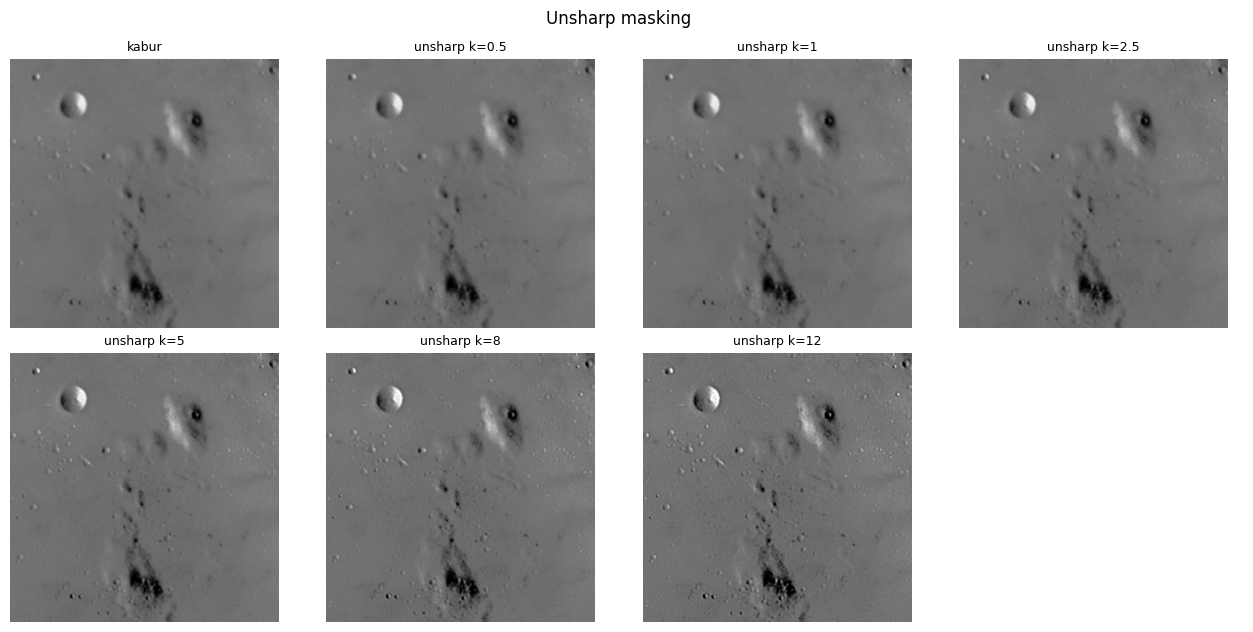

In [ ]:
#  7B.3 Penajaman: unsharp masking & batas penguatan
# Bikin gambar kabur dari gambar bersih (Gaussian 9x9, sigma 1.5), tugas kita menajamkannya lagi
kabur = cv2.GaussianBlur(bersih, (9, 9), 1.5)
f = kabur.astype(np.float64)                      # WAJIB float64 sebelum menajamkan
f_bar = cv2.GaussianBlur(f, (5, 5), 1.0)          # versi halus dari f, buat ngambil bagian detailnya

baris = []
hasil_tajam = [('kabur', kabur)]
for k in [0.5, 1, 2.5, 5, 8, 12]:
    g_raw = f + k * (f - f_bar)                   # g = f + k (f - f_bar)   (Eq. 3-55/3-56)
    terpotong = 100 * np.mean((g_raw < 0) | (g_raw > 255))   # persen piksel yang keluar rentang 0..255
    g_out = np.clip(g_raw, 0, 255).astype(np.uint8)          # clip dan uint8 baru di akhir
    baris.append({'k': k, 'PSNR (dB)': round(psnr(bersih, g_out), 2),
                  '% terpotong': round(terpotong, 2)})
    hasil_tajam.append((f'unsharp k={k}', g_out))
display(pd.DataFrame(baris))
tampil(hasil_tajam, judul='Unsharp masking', kolom=4)
# Perhatiin: PSNR naik dulu, lalu turun lagi kalau k kebesaran, dan % terpotong terus naik.

### 7C. Pipeline preprocessing akhir

Sekarang kita gabungin jadi satu fungsi yang dijalankan ke **semua gambar**, urutannya:

1. **Resize** ke ukuran seragam, biar semua gambar sama ukuran (model biasanya butuh ini).
2. **Abu-abu**, kalau warna gak dibutuhkan.
3. **Median 3×3** → redam derau dulu.
4. **CLAHE** → baru perbaiki kontras. Urutan ini penting: kalau kontras dinaikkan dulu, derau ikut menguat.
5. **Normalisasi 0–1**, soalnya model machine learning biasanya lebih suka input kecil.

Hasilnya disimpan dua versi: **PNG** (buat dilihat) dan **`.npy`** (array siap masuk model). Ini cuma contoh urutan. Buat tubes kamu, sesuaikan langkahnya dengan hasil EDA.

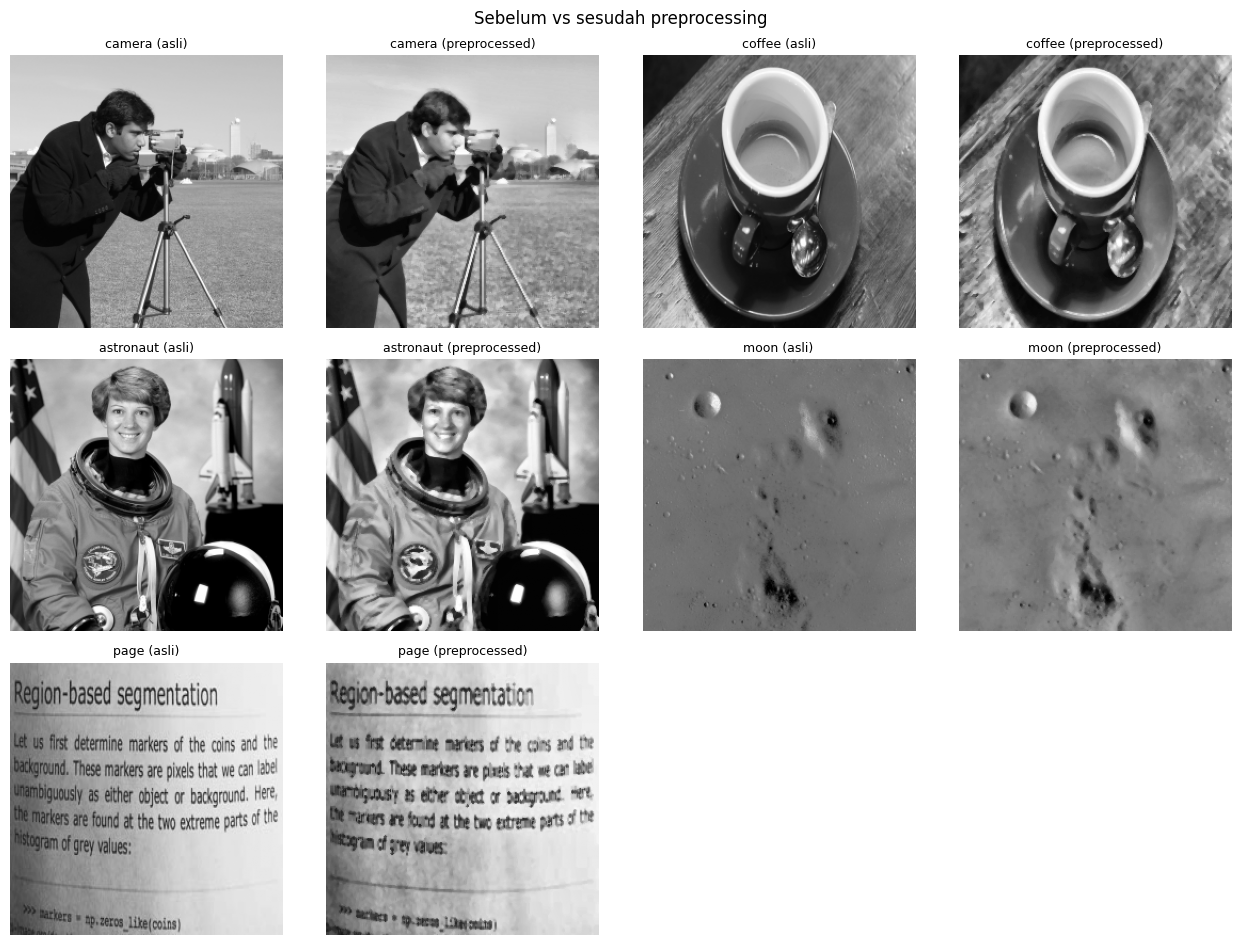

Bentuk array siap model: (5, 256, 256) | rentang: 0.003921568859368563 - 1.0
Tersimpan di: /content/PCD_Tubes/hasil


In [ ]:
#  7C. Pipeline preprocessing akhir untuk seluruh dataset
UKURAN = (256, 256)    # ukuran seragam (lebar, tinggi), sesuaikan kebutuhan model tubes kamu

def preprocess(rgb, ukuran=UKURAN, clip=2.0):
    # Urutan: resize -> abu-abu -> median 3x3 (buang derau) -> CLAHE (kontras) -> normalisasi 0..1
    im = cv2.resize(rgb, ukuran, interpolation=cv2.INTER_AREA)       # INTER_AREA bagus kalau memperkecil
    g = cv2.cvtColor(im, cv2.COLOR_RGB2GRAY)                         # jadi abu-abu
    g = cv2.medianBlur(g, 3)                                         # redam derau dulu
    g = cv2.createCLAHE(clipLimit=clip, tileGridSize=(8, 8)).apply(g)  # baru naikkan kontras lokal
    return g, (g.astype(np.float32) / 255.0)                         # (uint8 buat disimpan, float32 buat model)

hasil_pre, tampilan = {}, []
for nama, rgb in citra.items():
    g_u8, g_f32 = preprocess(rgb)                                    # proses tiap gambar
    hasil_pre[nama] = g_u8
    asli_g = ke_abu(cv2.resize(rgb, UKURAN, interpolation=cv2.INTER_AREA))  # versi asli (ukuran sama) buat pembanding
    tampilan += [(f'{nama} (asli)', asli_g), (f'{nama} (preprocessed)', g_u8)]
tampil(tampilan, judul='Sebelum vs sesudah preprocessing', kolom=4)

# Simpan hasil: PNG satu-satu (buat dilihat) dan satu file NPY (tumpukan array siap latih)
for nama, im in hasil_pre.items():
    cv2.imwrite(os.path.join(OUT_DIR, os.path.splitext(nama)[0] + '_pre.png'), im)
X = np.stack([im.astype(np.float32) / 255.0 for im in hasil_pre.values()])  # bentuk: (jumlah, tinggi, lebar)
np.save(os.path.join(OUT_DIR, 'X_preprocessed.npy'), X)
print('Bentuk array siap model:', X.shape, '| rentang:', float(X.min()), '-', float(X.max()))
print('Tersimpan di:', OUT_DIR)

### 8. (Opsional) Unduh hasil ke laptop

Ingat, file di Colab bisa hilang. Sel di bawah nge-zip semua hasil lalu mengunduhnya. Hapus tanda `#` di depan barisnya kalau mau dipakai.

In [ ]:
#  8. (Opsional) Unduh hasil ke komputer
# Hapus tanda '#' di depan baris di bawah buat ngunduh semua hasil dalam satu file zip.
# import shutil
# from google.colab import files
# shutil.make_archive('/content/hasil_preprocessing', 'zip', OUT_DIR)   # bungkus folder hasil jadi zip
# files.download('/content/hasil_preprocessing.zip')                    # unduh ke laptop